# Lab 1 — TCP grezzo e MQTT

## Prima di iniziare

**Teoria di riferimento**

- Blocco 0.1, «Scope, transport and versions»: MQTT chiede un flusso di byte ordinato e senza perdite.
- Blocco 0.1, «Remaining Length encoding»: come MQTT marca la fine di un pacchetto.
- Blocco 0.1, «QoS 0, 1 and 2 exchanges»: i pacchetti di QoS 0, 1 e 2 sui due salti.
- Blocco 0.1, «Header and payload size», «Per-message framing overhead» e «Three payloads, the same framing».

**Che cosa vediamo oggi**

1. TCP consegna byte, non messaggi: il confine fra due messaggi lo scrive l'applicazione.
2. La stessa finestra di un secondo costa da 48 byte a 6 kB secondo come la scriviamo.
3. Quanti byte mette MQTT attorno a un messaggio, a ogni QoS, contro TCP con la lunghezza davanti.

Il dataset del corso non serve: la finestra di dati è sintetica.

**Tempo**: circa un'ora e mezza. Parte 1 30 min, Parte 2 35, Parte 3 20, chiusura 10.

### Dove va questo laboratorio

Che cosa costa mandare una misura sulla rete, byte per byte?

| | domanda | output atteso |
|---|---|---|
| Parte 1 | TCP consegna messaggi o byte? | Byte: i confini fra i messaggi li scrive l'applicazione. |
| Parte 2 | Quanto pesa la stessa finestra in formati diversi? | Da 48 byte (un riassunto) a 6 kB (JSON): il formato è una scelta di progetto. |
| Parte 3 | Quanti byte aggiunge MQTT, a ogni QoS? | Pochi byte di intestazione, ma più pacchetti con QoS 1 e 2. |

In [62]:
import json
import struct

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iomtlab.net import TOPIC, synthetic_window, pack_window, unpack_window, encode_json, encoding_sizes
# TOPIC: il topic delle slide, "iomt/s01/sp/window" (18 caratteri)
# synthetic_window: una finestra di dati finta; pack_window, encode_json: due formati per scriverla in byte
# encoding_sizes: quanti byte occupa la finestra in vari formati
print("topic:", TOPIC, "-", len(TOPIC), "caratteri")

topic: iomt/s01/sp/window - 18 caratteri


## Parte 1 — TCP consegna byte, non messaggi


**Che cosa facciamo.** Il mittente manda 10 messaggi da 11 byte ciascuno, con 10 `sendall` separate.
Il ricevitore aspetta 0,3 secondi prima di cominciare a leggere; poi chiama `recv` finché il mittente
non chiude e, ogni volta, si segna quanti byte ha ricevuto.

**Che cosa ci aspettiamo.** Il mittente ha mandato 10 messaggi separati. Se la rete consegnasse
i messaggi uno per uno, come fa UDP, ogni `recv` restituirebbe un messaggio intero: vedremmo
10 `recv`, ciascuna da 11 byte.

Ma TCP non consegna messaggi: consegna **byte, uno dopo l'altro, in un'unica fila**. I byte che
arrivano si accumulano in attesa che il ricevitore li legga. Il nostro ricevitore aspetta 0,3 secondi
prima di leggere: in quel tempo sono arrivati tutti e 110 i byte. Allora la prima `recv` li prende
**tutti insieme**: una sola `recv`, 110 byte.

E in quei 110 byte non c'è scritto dove finiva un messaggio e cominciava il successivo.

**Perché ci interessa.** Chi scrive un protocollo deve dire lui dove finisce ogni messaggio. Nella
seconda cella mettiamo davanti a ogni messaggio 2 byte con la sua lunghezza: il ricevitore legge
prima la lunghezza, poi esattamente quel numero di byte. MQTT fa la stessa cosa con la Remaining
Length (Blocco 0.1, «Remaining Length encoding»; Parte 3).

10 sendall da 11 byte  ->  1 recv: [110] byte


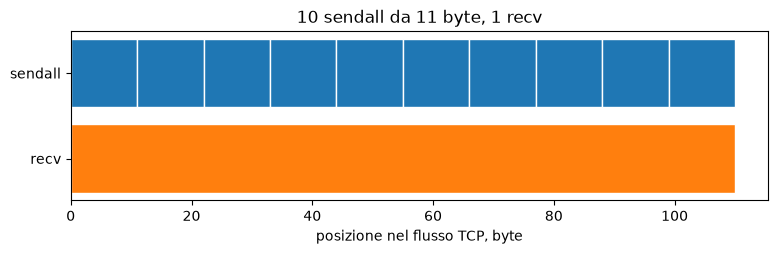

In [63]:
import socket
import threading
import time

ricevuti = []  # quanti byte restituisce ogni recv

def ricevitore(server):
    conn, _ = server.accept()  # aspetto che il mittente si colleghi: conn è il socket della connessione
    time.sleep(0.3)  # il ricevitore aspetta 0,3 s
    while True:
        dati = conn.recv(65536)  # prendo quello che c'è, al massimo 65536 byte
        if not dati:  # b"": il mittente ha chiuso
            break
        ricevuti.append(len(dati))
    conn.close()

server = socket.create_server(("127.0.0.1", 0))  # crea un socket in ascolto; porta 0 signficia che la sceglie il sistema
porta = server.getsockname()[1]  # la porta scelta
t = threading.Thread(target=ricevitore, args=(server,))  # il ricevitore gira su un altro thread
t.start() # thread inziia, ricevitore si connette al server

mittente = socket.create_connection(("127.0.0.1", porta)) # il mittente si collega
for k in range(10):
    mittente.sendall(b"A" * 11)  # dieci messaggi da 11 byte
mittente.close()

t.join()  # aspetto che il ricevitore finisca
server.close()
print(f"10 sendall da 11 byte  ->  {len(ricevuti)} recv: {ricevuti} byte")
# disegno il lfusos di byte
fig, ax = plt.subplots(figsize=(9, 2.2))
inizio = 0
for n in [11] * 10:                                   # i 10 sendall, uno dopo l'altro
    ax.barh("sendall", n, left=inizio, color="tab:blue", edgecolor="white")   # left: dove comincia il blocco
    inizio += n
inizio = 0
for n in ricevuti:                                    # le recv, una dopo l'altra
    ax.barh("recv", n, left=inizio, color="tab:orange", edgecolor="white")
    inizio += n
ax.invert_yaxis()                                     # sendall sopra, recv sotto
ax.set(xlabel="posizione nel flusso TCP, byte",
       title=f"10 sendall da 11 byte, {len(ricevuti)} recv")
plt.show()

Ora messaggi di lunghezze diverse, e davanti a ognuno scriviamo **2 byte di lunghezza davanti** a ognuno.
`struct.pack("!H", n)` scrive il numero `n` in 2 byte (big-endian); `struct.unpack` fa il contrario.
Il ricevitore arriva ancora in ritardo e trova tutto attaccato, ma leggendo prima la lunghezza
ritrova i messaggi uno per uno.

10 messaggi mandati, 10 ricevuti, identici: True
il primo messaggio: b'{"seq": 0, "nota": ""}'
la sua lunghezza, scritta davanti: b'\x00\x16' = 22 byte


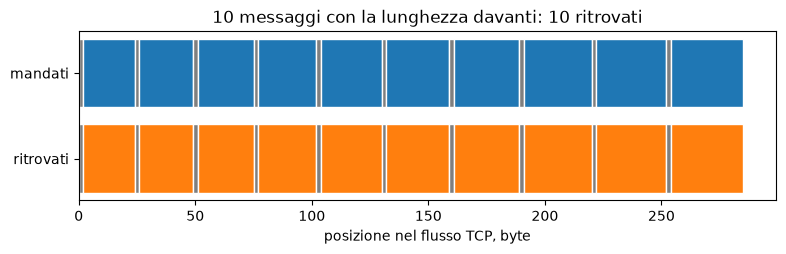

In [ ]:
import struct

def leggi_esattamente(conn, n):
    # Perché serve: recv(n) restituisce AL MASSIMO n byte, cioè quelli arrivati fino a quel momento.
    # Se ne sono arrivati meno, ne restituisce meno: allora bisogna chiamarla di nuovo per il resto.
    dati = b""      # i byte raccolti finora: all'inizio nessuno
    while len(dati) < n:    # finché ne mancano
        pezzo = conn.recv(n - len(dati))   # chiedo solo quelli che mancano, non di più
        if not pezzo:  # recv restituisce b"" (zero byte) solo quando il mittente ha chiuso
            return None  # la connessione è finita prima di avere n byte
        dati += pezzo   # aggiungo il pezzo a quelli già raccolti
    return dati   # adesso len(dati) == n

messaggi_ricevuti = []

def ricevitore_con_lunghezza(server):
    conn, _ = server.accept()
    time.sleep(0.3)  # anche qui il ricevitore arriva in ritardo
    while True:
        testa = leggi_esattamente(conn, 2)   # 1. leggo i 2 byte della lunghezza
        if testa is None:
            break
        n = struct.unpack("!H", testa)[0]   # dai 2 byte al numero n; unpack restituisce una tupla, [0] il primo valore
        messaggi_ricevuti.append(leggi_esattamente(conn, n))   # 2. leggo esattamente n byte: un messaggio intero
    conn.close()

msgs = [json.dumps({"seq": k, "nota": "x" * k}).encode() for k in range(10)] # list comprehension: 10 messaggi di lunghezze diverse
# json.dumps trasforma il dizionario in testo JSON; encode() trasforma il testo in byte, che è ciò che si manda sulla rete

server = socket.create_server(("127.0.0.1", 0))
porta = server.getsockname()[1]
t = threading.Thread(target=ricevitore_con_lunghezza, args=(server,))
t.start()

mittente = socket.create_connection(("127.0.0.1", porta))
for m in msgs:
    mittente.sendall(struct.pack("!H", len(m)) + m)   # davanti a ogni messaggio, 2 byte con la sua lunghezza
mittente.close()

t.join()
server.close()
print(f"{len(msgs)} messaggi mandati, {len(messaggi_ricevuti)} ricevuti, identici: {messaggi_ricevuti == msgs}")
print("il primo messaggio:", messaggi_ricevuti[0])
print("la sua lunghezza, scritta davanti:", struct.pack("!H", len(msgs[0])), "=", len(msgs[0]), "byte")

fig, ax = plt.subplots(figsize=(9, 2.2))
inizio = 0
for m in msgs:    # i messaggi mandati, uno dopo l'altro
    ax.barh("mandati", 2, left=inizio, color="tab:gray", edgecolor="white")           # i 2 byte della lunghezza
    ax.barh("mandati", len(m), left=inizio + 2, color="tab:blue", edgecolor="white")  # il messaggio
    inizio += 2 + len(m)
inizio = 0
for m in messaggi_ricevuti:            # i messaggi che il ricevitore ha ritrovato
    ax.barh("ritrovati", 2, left=inizio, color="tab:gray", edgecolor="white")
    ax.barh("ritrovati", len(m), left=inizio + 2, color="tab:orange", edgecolor="white")
    inizio += 2 + len(m)
ax.invert_yaxis()  # mandati sopra, ritrovati sotto
ax.set(xlabel="posizione nel flusso TCP, byte",
       title=f"{len(msgs)} messaggi con la lunghezza davanti: {len(messaggi_ricevuti)} ritrovati")
plt.show()


## Parte 2 — Il formato del payload

> **Domanda.** Quanto pesa la stessa finestra in formati diversi? **Output atteso.** Da 48 byte (un riassunto) a 6 kB (JSON): il formato è una scelta di progetto.

Né TCP né MQTT dicono che cosa c'è nel payload (Blocco 0.1, «Three payloads, the same
framing»). Codifico la stessa finestra di un secondo, 50 campioni per 6 canali,
in cinque modi e conto i byte. La finestra è sintetica, con le ampiezze di un telefono in
tasca durante la camminata: oggi si misurano byte, non movimento. Il formato `int16` è quello
di `pack_window`: 11 byte di intestazione e ogni canale quantizzato sul fondo scala del
dispositivo. Il riassunto sono media e deviazione standard di ogni canale: 12 numeri.

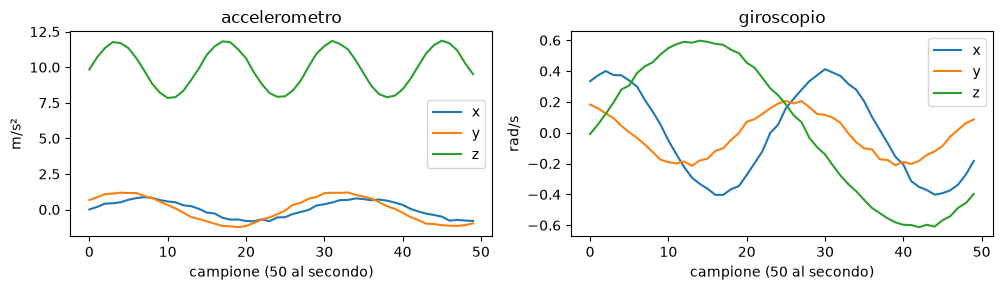

In [65]:
t0_ms, X = synthetic_window()   # la finestra: 50 campioni × 6 canali; t0_ms è l'istante iniziale, in ms

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3))   # due grafici affiancati
a1.plot(X[:, 0:3])                                    # colonne 0, 1, 2: i tre assi dell'accelerometro
a1.set(title="accelerometro", xlabel="campione (50 al secondo)", ylabel="m/s²")
a1.legend(["x", "y", "z"])
a2.plot(X[:, 3:6])                                    # colonne 3, 4, 5: i tre assi del giroscopio
a2.set(title="giroscopio", xlabel="campione (50 al secondo)", ylabel="rad/s")
a2.legend(["x", "y", "z"])
plt.tight_layout()
plt.show()

{'json': 6029, 'json_3': 2049, 'float32': 1200, 'int16': 611, 'features': 144}


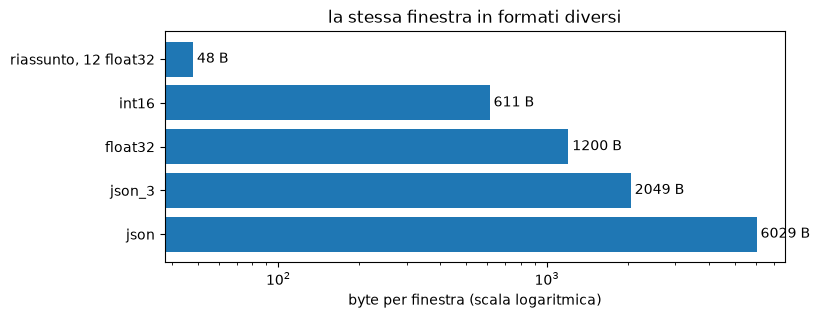

errore massimo dovuto a int16, per canale: [0.00119 0.00116 0.00115 0.00026 0.00027 0.00026] (m/s² e rad/s)
i primi 70 caratteri del JSON: b'{"seq":0,"t0":2000,"x":[[0.006286511054669665,0.6709657249094773,9.842'


In [ ]:
# 1. quanti byte occupa la stessa finestra in ogni formato
# X è una finestra di dati: 50 campioni (1 s a 50 Hz) × 6 canali (3 assi dell'accelerometro, 3 del giroscopio).
# encoding_sizes la scrive in vari formati e restituisce un dizionario  {nome del formato: quanti byte}.
sizes = encoding_sizes(X, t0_ms, decimals=3)
print(sizes) # vediamo cosa c'è dentro
sizes.pop("features")  # pop toglie una voce dal dizionario: questo formato qui non ci serve (lo vedremo in un altro Lab)

# 2. introducaimo un formato in più,: il riassunto della finestra 
# invece dei 300 numeri della finestra, mando solo media e deviazione standard di ogni canale: 6 + 6 = 12 numeri
medie = X.mean(axis=0)    # axis=0: la media lungo i 50 campioni, una per ognuno dei 6 canali
deviazioni = X.std(axis=0)   # lo stesso per la deviazione standard
numeri = np.concatenate([medie, deviazioni])   # concatenate: un solo array con i 12 numeri
riassunto = numeri.astype(">f4").tobytes()  # ">f4": float32 (4 byte a numero), byte in ordine big-endian
 # tobytes(): i byte veri e propri, pronti da spedire
sizes["riassunto, 12 float32"] = len(riassunto) # 12 numeri × 4 byte = 48 byte

# 3. il grafico
nomi = list(sizes.keys())                # i nomi dei formati
byte = list(sizes.values())              # i byte di ciascuno, nello stesso ordine
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(nomi, byte)                      # barh: barre orizzontali, una per formato
ax.set_xscale("log")                     # scala logaritmica: i valori vanno da 48 a più di 6000
ax.set(xlabel="byte per finestra (scala logaritmica)", title="la stessa finestra in formati diversi")
for k, b in enumerate(byte):             # enumerate dà la posizione k e il valore b
    ax.text(b, k, f" {b} B", va="center")   # scrive il numero accanto alla barra k
plt.show()

#  4. che cosa si perde con int16, e com'è fatto il JSON
# pack_window scrive la finestra in int16 (2 byte a numero); unpack_window la rilegge.
# unpack_window restituisce tre cose; a noi serve solo la terza, i dati: le altre due le mettiamo in _ (un nome per «non serve»)
_, _, X_riletta = unpack_window(pack_window(0, t0_ms, X))
errore = np.abs(X_riletta - X).max(axis=0)  
print("errore massimo dovuto a int16, per canale:", errore.round(5), "(m/s² e rad/s)")
print("i primi 70 caratteri del JSON:", encode_json(0, t0_ms, X)[:70])   # [:70]: i primi 70 caratteri

### Sda scrivere — il payload di una decisione (circa 15 minuti)

**Teoria**: Blocco 0.1, «Per-message framing overhead». Invece dei dati, il nodo può mandare solo la sua conclusione, la *decisione*: un numer di classe (per esempio 2 = «sta camminando») con la sua confidenza. Il contenuto è pochi byte cosi!

**Che cosa scrivere.** `pack_decision(t_ms, classe, confidenza)` deve restituire **6 byte**,
big-endian, nell'ordine:

| campo | tipo `struct` | byte | valore |
|---|---|---|---|
| istante della decisione in ms | `I` (uint32) | 4 | `t_ms` modulo 2³² |
| classe | `B` (uint8) | 1 | da 0 a 4 |
| confidenza | `B` (uint8) | 1 | in percento intero, da 0 a 100 |

`unpack_decision(b)` fa il contrario e restituisce `(t_ms, classe, confidenza)` con la
confidenza fra 0 e 1. Il formato è `"!IBB"`: `!` vuol dire big-endian e niente riempimento.

Si scrive solo dentro la funzione; la cella successiva la controlla. Se non fate in tempo, il notebook prosegue lo stesso: la decisione resta fuori dalla tabella della Parte 3.

In [7]:
import struct

# ── che cosa dovete scrivere
# Una «decisione» è il risultato di un algoritmo, ad esempio un classificatore, per una finestra: tre numeri.
#   t_ms  l'istante, in millisecondi   es. 123456
#   classe  come è stata classificata la finestra: un intero da 0 a 4 es. 2
#   confidenza  quanto è sicuro, un numero fra 0 e 1 es. 0.934
# Invece di mandarli come testo, li scriviamo in 6 byte, con struct (slide «Python: struct, numeri in byte»):
#   4 byte per t_ms   formato I  (intero da 0 a 4 294 967 295)
#   1 byte per la classe formato B  (intero da 0 a 255)
#   1 byte per la confidenza formato B: la scriviamo in percento, un intero da 0 a 100 (0.934 -> 93)
# Il formato completo è "!IBB": ! = ordine dei byte di rete, poi I, B, B.

def pack_decision(t_ms, classe, confidenza):
    """Dai tre numeri ai 6 byte."""
    # 1. la confidenza in percento
    # 2. t_ms in 4 byte: se è più grande, tenete il resto della divisione per 2**32 (t_ms % 2**32) <- perchè?
    # 3. la classe è un numero
    raise NotImplementedError    # cancellate questa riga quando avete scritto la funzione

def unpack_decision(b):
    """Dai 6 byte ai tre numeri: (t_ms, classe, confidenza fra 0 e 1)."""
   
    raise NotImplementedError    # cancellate questa riga quando avete scritto la funzione

In [6]:
# controllo: per t_ms = 123456, classe 2, confidenza 0,934 i 6 byte giusti sono 00 01 e2 40 02 5d
# (123456 = 0x0001e240 su 4 byte; classe 2 = 0x02; 93 % = 0x5d)
try:
    b = pack_decision(123456, 2, 0.934)
    print(b.hex(" "), "-> giusto" if b == bytes.fromhex("0001e240025d") else "-> diverso da 00 01 e2 40 02 5d")
    print("e all'indietro:", unpack_decision(b))
except NotImplementedError:
    print("non ancora scritta: completa pack_decision e unpack_decision nella cella sopra")

non ancora scritta: completa pack_decision e unpack_decision nella cella sopra


**Da discutere**

1. Quanta informazione perdi arrotondando la confidenza al percento intero? Per che cosa la userebbe chi riceve?
2. La classe occupa un byte, ma 5 classi stanno in 3 bit: vale la pena risparmiare quei bit, visto il resto del messaggio (Parte 3)?

## Parte 3 — Quanti byte aggiunge MQTT

> **Domanda.** Quanti byte aggiunge MQTT attorno a un messaggio, a ogni QoS? **Output atteso.** Una ventina di byte, quasi tutti per il topic; con QoS 1 e 2, i pacchetti di conferma.

Calcoliamo i byte con le regole del pacchetto PUBLISH (Blocco 0.1, «PUBLISH packet», «Header and payload size»):

| parte | byte |
|---|---|
| tipo del pacchetto e flag | 1 |
| Remaining Length: quanti byte seguono | 1 se meno di 128, 2 fino a 16 383 |
| lunghezza del topic, poi il topic | 2 + 18 |
| identificativo del pacchetto, solo con QoS 1 e 2 | 2 |
| i dati | quanti sono |

Le conferme sono pacchetti da 4 byte: una (PUBACK) con QoS 1, tre (PUBREC, PUBREL, PUBCOMP) con QoS 2.
Per confronto, TCP con la lunghezza davanti (Parte 1) aggiunge solo 2 byte.

pack_decision non è ancora scritta: la decisione resta fuori dalla tabella


,dati,TCP + lunghezza,MQTT QoS 0,MQTT QoS 1,MQTT QoS 2
messaggio,,,,,
"riassunto, 48 byte",48,50,70,76,84
finestra int16,611,613,634,640,648
finestra JSON,2049,2051,2072,2078,2086


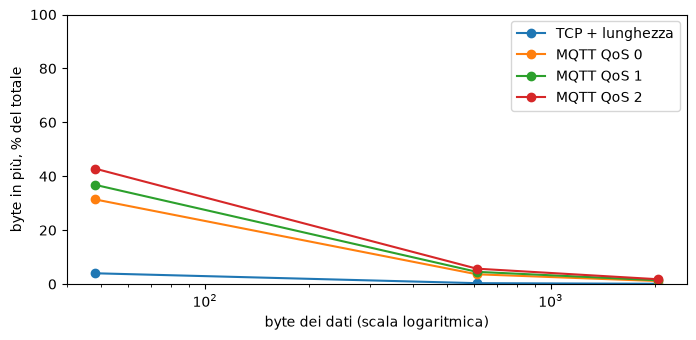

In [ ]:
# 1. i byte di un messaggio MQTT, con le regole della tabella sopra
def byte_mqtt(topic, dati, qos):
    resto = 2 + len(topic) + len(dati)  # lunghezza del topic (2 byte), il topic, i dati
    if qos > 0:
        resto += 2   # con QoS 1 e 2: l'identificativo del pacchetto
    if resto < 128:  # la Remaining Length occupa 1 byte fino a 127,
        rl = 1
    else: # 2 byte fino a 16 383 (i nostri messaggi stanno qui)
        rl = 2
    publish = 1 + rl + resto   # 1 byte di tipo, la Remaining Length, il resto
    conferme = {0: 0, 1: 4, 2: 12}[qos]   # QoS 1: PUBACK; QoS 2: PUBREC, PUBREL, PUBCOMP
    return publish + conferme

# 2. i messaggi da confrontare, dal più piccolo al più grande ──────────────────────────
messaggi = {}   # dizionario: nome del messaggio -> i suoi byte
try:
    messaggi["decisione, 6 byte"] = pack_decision(t0_ms, 2, 0.93)   # la funzione scritta da voi
except NotImplementedError:
    print("pack_decision non è ancora scritta: la decisione resta fuori dalla tabella")
messaggi["riassunto, 48 byte"] = riassunto        # il riassunto della Parte 2
messaggi["finestra int16"] = pack_window(0, t0_ms, X)
messaggi["finestra JSON"] = encode_json(0, t0_ms, X, decimals=3)

#  3. la tabella: una riga per messaggio, una colonna per modo di mandarlo
righe = []
for nome, dati in messaggi.items():
    righe.append({"messaggio": nome,
                  "dati": len(dati),
                  "TCP + lunghezza": len(dati) + 2,
                  "MQTT QoS 0": byte_mqtt(TOPIC, dati, 0),
                  "MQTT QoS 1": byte_mqtt(TOPIC, dati, 1),
                  "MQTT QoS 2": byte_mqtt(TOPIC, dati, 2)})
tab = pd.DataFrame(righe).set_index("messaggio")  # dalla lista di dizionari a una tabella
display(tab)

#  4. il grafico: quanta parte dei byte NON sono i dati
fig, ax = plt.subplots(figsize=(8, 3.5))
for col in ["TCP + lunghezza", "MQTT QoS 0", "MQTT QoS 1", "MQTT QoS 2"]:
    quota = 100 * (tab[col] - tab["dati"]) / tab[col]   # i byte in più, in percentuale del totale
    ax.plot(tab["dati"], quota, "o-", label=col)        # "o-": punti uniti da una linea
ax.set_xscale("log")                              # i messaggi vanno da 6 a 2000 byte
ax.set_ylim(0, 100)
ax.set(xlabel="byte dei dati (scala logaritmica)", ylabel="byte in più, % del totale")
ax.legend()
plt.show()

La differenza fra `MQTT QoS 0` e `dati` è quello che aggiunge MQTT: 22–23 byte a messaggio, di cui 20 per il topic. Con QoS 1 e 2 si aggiungono 2 byte di identificativo e le conferme, 4 o 12 byte. Per la decisione da 6 byte i byte in più sono molti più dei dati; per la finestra quasi non contano.